# 06. Czy alfa potyliczna ostrzega przed lapsem z wyprzedzeniem? (COG-BCI, zadanie PVT)

Zadanie B5 (strumień „B. Dane i dowody”, SHOULD). Pytanie: **czy alfa potyliczna (O1/O2) mierzona przy otwartych oczach
przewiduje lapsy czujności (czas reakcji > 500 ms) w *następnej* minucie?**

Od odpowiedzi zależy, czy produkt może dawać **wczesne ostrzeżenie**: gdy wskaźnik EEG rośnie, panel prosi o krótki test
reakcji, *zanim* człowiek faktycznie „odpłynie”. Jeśli alfa nie wyprzedza lapsów, produkt może jedynie wykrywać lapsy
(np. zamykanie oczu) w chwili, gdy już trwają.

**Dane:** COG-BCI (Hinss i in., Zenodo 7413650), zadanie PVT: ok. 10 minut, 90 bodźców w odstępach 2–10 s, oczy otwarte.
Do 29 osób × 3 sesje (w odstępie tygodnia). Czasy reakcji bierzemy ze znaczników w zapisie EEG (13 = bodziec, 14 = reakcja,
12 = błąd w przerwie, czyli falstart), tak jak w notebooku 05. Pliki `behavioral/PVT.mat` okazały się bezużyteczne (sekcja 1).

**Przetwarzanie udaje nasz sprzęt i nasz produkt** (`src/wachta/features.py`, `config.py`, `baseline.py`):
8 kanałów (F3, F4, C3, C4, P3, P4, O1, O2), referencja Fp1, filtr 1–40 Hz, 250 Hz, okna 2 s z krokiem 1 s,
odrzucenie okien z amplitudą szczyt-szczyt > 300 µV. Kalibracja osobista w każdym nagraniu: pierwsze 60 czystych okien
(mediana i MAD), potem z-score. Wskaźnik szybki produktu = mediana z-score'u wyrazistości alfy z ostatnich 5 okien.

**Zasady analizy:**
- jednostką jest **osoba**: AUC liczymy osobno dla każdej osoby, a potem patrzymy na rozkład (mediana, IQR, przedział
  ufności z bootstrapu po osobach). Nie wrzucamy okien różnych ludzi do jednego worka;
- prognoza jest **ściśle w przód**: predyktor z okna [τ − 60 s, τ − 2 s], cel = co najmniej jeden laps w [τ, τ + 60 s)
  (i wariant 30 s). Przerwa 2 s chroni przed „przeciekiem” przez filtr o zerowej fazie;
- alfa musi pobić dwie proste bazy: (a) **czas od początku zadania**, (b) **zachowanie w poprzedniej minucie**
  (średni RT i liczba lapsów), bo kto już reaguje wolno, zwykle dalej reaguje wolno;
- modele z kilkoma cechami oceniamy tylko na danych, których model nie widział: (1) bez danej osoby (leave-one-person-out),
  (2) w obrębie osoby, „w przód w czasie”: sesję k przewiduje model uczony na wcześniejszych sesjach tej osoby.

In [1]:
%pip install -q mne remotezip


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /tmp/claude-0/work/v/bin/python3 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import shutil
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from remotezip import RemoteZip
from scipy.signal import welch
from scipy.stats import wilcoxon
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 85, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 200)

OUR_CH = ["F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2"]
FS = 250
WIN_S, STEP_S = 2.0, 1.0
REJECT_UV = 300          # window rejected if peak-to-peak > 300 µV on any channel (config.reject_uv)
CAL_WINDOWS = 60         # first clean windows = personal baseline (config.cal_windows)
SMOOTH = 5               # causal median over 5 windows = product "fast index" (config.smooth_windows)
EPS = 1e-12
LAPSE_MS = 500           # classic PVT lapse
LAPSE_B_MS = 355         # PVT-B lapse threshold (Basner et al. 2011)

SUBJECTS = [f"sub-{i:02d}" for i in range(1, 30)]
SESSIONS = ["S1", "S2", "S3"]

DATA = Path("/content/data") if Path("/content").exists() else Path.home() / ".cache" / "wachta-eeg"
RAW_DIR = DATA / "cogbci-pvt-b5"           # extracted .set/.fdt, deleted after each subject
RES_DIR = DATA / "cogbci-pvt-b5-results"   # small per-recording tables, kept so re-runs skip downloads
RES_DIR.mkdir(parents=True, exist_ok=True)
COG_URL = "https://zenodo.org/records/7413650/files/{sub}.zip?download=1"

## 1. Pobranie danych i kontrola plików behawioralnych

Z każdego archiwum (~1,1 GB na osobę) wyciągamy przez zapytania HTTP z zakresem (`remotezip`) tylko `PVT.set` i `PVT.fdt`
(~77 MB na sesję), liczymy małe tabele (cechy okien 2 s i znaczniki PVT) i od razu kasujemy surowe pliki.
Tabele zostają w katalogu cache poza repo, więc ponowne uruchomienie nie pobiera danych drugi raz (pełne pobranie: ok. 30–40 min).

Najpierw sprawdzamy pliki `behavioral/PVT.mat`. Spis archiwum podaje sumę kontrolną CRC każdego pliku, więc nie trzeba nic pobierać.

In [3]:
crc = []
for sub in SUBJECTS:
    with RemoteZip(COG_URL.format(sub=sub)) as z:
        crc += [(sub, i.filename.split("/ses-")[1][:2], i.CRC, i.file_size) for i in z.infolist()
                if i.filename.endswith("behavioral/PVT.mat")]
crc = pd.DataFrame(crc, columns=["subject", "session", "crc32", "bytes"])
print(crc.groupby(["crc32", "bytes"]).size().rename("liczba plików").to_string())
print(f"\nróżnych plików PVT.mat wśród {len(crc)}: {crc.crc32.nunique()}")

crc32       bytes
1922564557  2988     24
2782752299  2988     63

różnych plików PVT.mat wśród 87: 2


**Pliki `PVT.mat` nie należą do poszczególnych nagrań:** wśród 87 plików (29 osób × 3 sesje) są tylko dwa różne
(ta sama suma CRC i rozmiar u różnych osób i sesji; liczby wyżej). Sprawdziliśmy też ręcznie plik `sub-01`:
czasy reakcji z `.mat` nie korelują z czasami ze znaczników EEG (r ≈ −0,1), a rozkład przerw ISI jest inny.
To wygląda na jeden lub dwa pliki skopiowane do wszystkich folderów. **Dlatego czasy reakcji bierzemy wyłącznie ze znaczników 13/14
w zapisie EEG**, tak jak w notebooku 05. Te znaczniki są spójne (90 bodźców, 90 reakcji, przerwy 2–10 s).

In [4]:
PVT_CODES = {"11", "12", "13", "14", "15"}   # trial/ISI start, ISI error (false start), stimulus, response, end


def eeg_window_table(raw):
    """Hardware-like pipeline: 8 channels, Fp1 reference, 1-40 Hz, 250 Hz, 2 s windows / 1 s step.

    Features follow src/wachta/features.py (alpha_prom, alpha_occ). `t_end` is the end of the window,
    i.e. the moment the product would know the value.
    """
    r = raw.copy()
    r.set_eeg_reference(["Fp1"], projection=False)       # BrainAccess MINI: hardware reference at Fp1
    r.pick(OUR_CH).reorder_channels(OUR_CH)
    r.filter(1.0, 40.0, fir_design="firwin", verbose=False).resample(FS)
    ep = mne.make_fixed_length_epochs(r, duration=WIN_S, overlap=WIN_S - STEP_S, preload=True)
    x = ep.get_data() * 1e6                              # µV
    ptp = np.ptp(x, axis=-1).max(1)
    f, p = welch(x, FS, nperseg=int(WIN_S * FS), axis=-1)
    dfh = f[1] - f[0]
    occ = p[:, 6:8].mean(1)                              # mean PSD over O1/O2
    bmean = lambda lo, hi: occ[:, (f >= lo) & (f <= hi)].mean(1)
    alpha_pow = p[:, 6:8][:, :, (f >= 8) & (f <= 12)].sum(-1) * dfh
    t_start = ep.events[:, 0] / FS
    return pd.DataFrame({
        "t_end": t_start + WIN_S,
        "alpha_prom": np.log10((bmean(8, 12) + EPS) / (np.sqrt(bmean(5, 7) * bmean(14, 16)) + EPS)),
        "alpha_occ": np.log10(alpha_pow.mean(1) + EPS),
        "ptp_uv": ptp,
    })


def fetch_and_process(sub, retries=4):
    """Range-request only PVT.set/.fdt of one subject, compute small tables, delete raw files."""
    done = lambda ses: (RES_DIR / f"{sub}_{ses}_win.csv").exists()
    if all(done(s) for s in SESSIONS):
        return "cache"
    for attempt in range(retries):
        try:
            with RemoteZip(COG_URL.format(sub=sub)) as z:
                names = [n for n in z.namelist() if n.endswith(("/eeg/PVT.set", "/eeg/PVT.fdt"))]
                for n in names:
                    ses = n.split("/ses-")[1][:2]
                    if ses in SESSIONS and not done(ses):
                        z.extract(n, RAW_DIR / sub)
            break
        except Exception as e:                           # network hiccups on Zenodo
            print(f"  {sub}: attempt {attempt + 1} failed ({e})")
            time.sleep(30 * (attempt + 1))
    for path in sorted((RAW_DIR / sub).rglob("ses-*/eeg/PVT.set")):
        ses = path.parent.parent.name[4:]
        try:
            raw = mne.io.read_raw_eeglab(path, preload=True)
            ann = pd.DataFrame({"onset": raw.annotations.onset, "code": raw.annotations.description})
            ann[ann.code.isin(PVT_CODES)].to_csv(RES_DIR / f"{sub}_{ses}_events.csv", index=False)
            eeg_window_table(raw).round(5).to_csv(RES_DIR / f"{sub}_{ses}_win.csv", index=False)
        except Exception as e:
            print(f"  {sub} {ses}: processing error ({e})")
    shutil.rmtree(RAW_DIR / sub, ignore_errors=True)
    return "downloaded"

In [5]:
t_start = time.time()
for sub in SUBJECTS:
    status = fetch_and_process(sub)
    if status != "cache":
        print(f"{sub}: pobrane ({time.time() - t_start:.0f} s od startu)")
print("gotowe")

gotowe


## 2. Nagrania, kalibracja, lapsy

Dla każdego nagrania: początek zadania (pierwszy znacznik 11), koniec (15), kalibracja z pierwszych 60 czystych okien po starcie
zadania (ok. 1 minuta). Wskaźnik produktu istnieje dopiero po kalibracji, więc wszystko, co przewidujemy, zaczyna się po niej.

In [6]:
def trials_from_events(ev):
    """Stimulus (13) followed by a response (14) before the next stimulus -> one trial with RT in ms.
    A response logged at the same instant as the stimulus (RT < 100 ms) is an anticipation / key already
    pressed: it is counted as a false start and its RT is set to NaN (neither a lapse nor a valid reaction)."""
    on, code = ev.onset.values, ev.code.astype(str).values
    stim, resp = on[code == "13"], on[code == "14"]
    rows = []
    for i, s in enumerate(stim):
        nxt_stim = stim[i + 1] if i + 1 < len(stim) else np.inf
        r = resp[(resp >= s) & (resp < nxt_stim)]
        rows.append((s, (r[0] - s) * 1000 if len(r) else np.nan))
    tr = pd.DataFrame(rows, columns=["t", "rt_ms"])
    tr["anticip"] = tr.rt_ms < 100
    tr.loc[tr.anticip, "rt_ms"] = np.nan
    tr["t_resp"] = tr.t + tr.rt_ms / 1000
    return tr


def false_starts(ev):
    """Two candidate markers: ISI-error trigger (12), and responses with no stimulus since the last trial start (11)."""
    code, on = ev.code.astype(str).values, ev.onset.values
    n12 = int((code == "12").sum())
    orphan, armed = 0, False
    for c in code:
        if c == "11":
            armed = False
        elif c == "13":
            armed = True
        elif c == "14":
            if not armed:
                orphan += 1
            armed = False
    return n12, orphan


def robust_baseline(x):
    """Median and scaled MAD with the same fallbacks as src/wachta/baseline.py."""
    c = np.median(x)
    s = np.median(np.abs(x - c)) * 1.4826
    if s <= 1e-6:
        s = x.std() if x.std() > 1e-6 else 1.0
    return c, s


def causal_median(z, n=SMOOTH):
    """Product fast index: median of the last n windows, NaN-aware, needs (n+1)//2 valid values."""
    out = np.full(len(z), np.nan)
    for i in range(len(z)):
        v = z[max(0, i - n + 1): i + 1]
        v = v[~np.isnan(v)]
        if len(v) >= (n + 1) // 2:
            out[i] = np.median(v)
    return out


def prepare_recording(sub, ses):
    ev = pd.read_csv(RES_DIR / f"{sub}_{ses}_events.csv", dtype={"code": str})
    W = pd.read_csv(RES_DIR / f"{sub}_{ses}_win.csv")
    code = ev.code.values
    t0 = ev.onset[code == "11"].min()
    t1 = ev.onset[code == "15"].max() if (code == "15").any() else ev.onset.max()
    tr = trials_from_events(ev)
    W = W[(W.t_end - WIN_S >= t0) & (W.t_end <= t1)].reset_index(drop=True)   # task period only
    W["bad"] = W.ptp_uv > REJECT_UV
    clean = W.index[~W.bad]
    cal = clean[:CAL_WINDOWS]
    cal_end = W.t_end[cal[-1]]
    for col in ["alpha_prom", "alpha_occ"]:
        c, s = robust_baseline(W.loc[cal, col].values)
        z = (W[col] - c) / s
        z[W.bad] = np.nan
        z[W.t_end <= cal_end] = np.nan            # the product has no z-score until calibration is done
        W[col + "_z"] = z
    W["fast"] = causal_median(W.alpha_prom_z.values)
    fs12, orphan = false_starts(ev)
    info = dict(subject=sub, session=ses, t0=t0, t1=t1, cal_end=cal_end, dur_min=(t1 - t0) / 60,
                cal_min=(cal_end - t0) / 60, n_trials=len(tr), n_anticip=int(tr.anticip.sum()), n_no_resp=int((tr.rt_ms.isna() & ~tr.anticip).sum()),
                rt_median=tr.rt_ms.median(), lapses500=int((tr.rt_ms > LAPSE_MS).sum()),
                lapses355=int((tr.rt_ms > LAPSE_B_MS).sum()), isi_error_12=fs12, orphan_resp=orphan,
                eeg_rej_pct=100 * W.bad.mean())
    return W, tr, info

In [7]:
ANCHOR_STEP = 10     # s between prediction times tau
PRED_S = 60          # predictor window [tau - 60 s, tau - GAP]
GAP_S = 2            # zero-phase 1 Hz FIR smears ~1.7 s, so EEG windows must end >= 2 s before tau
MIN_CLEAN = 20       # predictor needs this many clean 2 s windows


def anchor_table(W, tr, info, horizons=(60, 30)):
    """One row per prediction time tau: EEG + behaviour from the past, lapse targets from the future."""
    rows = []
    t0, t1, cal_end = info["t0"], info["t1"], info["cal_end"]
    taus = np.arange(cal_end + PRED_S, t1 - min(horizons) + 1e-9, ANCHOR_STEP)
    te, z, zo, fast = W.t_end.values, W.alpha_prom_z.values, W.alpha_occ_z.values, W.fast.values
    for tau in taus:
        m = (te > tau - PRED_S) & (te <= tau - GAP_S)
        ok = m & ~np.isnan(z)
        past = tr[(tr.t >= tau - PRED_S) & (tr.t_resp < tau)]          # only trials already answered
        row = dict(subject=info["subject"], session=info["session"], tau=tau, tot_min=(tau - t0) / 60,
                   n_clean=int(ok.sum()),
                   alpha_mean=np.nanmean(z[m]) if ok.sum() >= MIN_CLEAN else np.nan,
                   alpha_max=np.nanmax(fast[m]) if ok.sum() >= MIN_CLEAN else np.nan,
                   occ_mean=np.nanmean(zo[m]) if ok.sum() >= MIN_CLEAN else np.nan,
                   prev_rt=past.rt_ms.mean() if len(past) else np.nan,
                   prev_lapses=int((past.rt_ms > LAPSE_MS).sum()),
                   prev_slow=int((past.rt_ms > LAPSE_B_MS).sum()))
        for h in horizons:
            fut = tr[(tr.t >= tau) & (tr.t < tau + h)]
            row[f"y{h}"] = int((fut.rt_ms > LAPSE_MS).any()) if tau + h <= t1 else np.nan
            row[f"yb{h}"] = int((fut.rt_ms > LAPSE_B_MS).any()) if tau + h <= t1 else np.nan
        rows.append(row)
    return pd.DataFrame(rows)


RECS, WINS, TRIALS, ANCH = [], {}, {}, []
for sub in SUBJECTS:
    for ses in SESSIONS:
        if not (RES_DIR / f"{sub}_{ses}_win.csv").exists():
            continue
        W, tr, info = prepare_recording(sub, ses)
        RECS.append(info)
        WINS[sub, ses], TRIALS[sub, ses] = W, tr
        ANCH.append(anchor_table(W, tr, info))
RECS = pd.DataFrame(RECS)
ANCH = pd.concat(ANCH, ignore_index=True)
print(f"{RECS.subject.nunique()} osób, {len(RECS)} nagrań PVT, {len(ANCH)} punktów predykcji (co {ANCHOR_STEP} s)")

29 osób, 87 nagrań PVT, 3962 punktów predykcji (co 10 s)


In [8]:
cols = ["dur_min", "cal_min", "n_trials", "n_anticip", "n_no_resp", "rt_median", "lapses500", "lapses355", "isi_error_12",
        "orphan_resp", "eeg_rej_pct"]
print("Na nagranie (mediana [min–max]):")
for c in cols:
    print(f"  {c:14s} {RECS[c].median():8.1f}  [{RECS[c].min():.1f}–{RECS[c].max():.1f}]")
per_sub = RECS.groupby("subject")[["lapses500", "lapses355", "isi_error_12"]].sum()
print(f"\nlapsy > 500 ms: razem {RECS.lapses500.sum()} w {len(RECS)} nagraniach; "
      f"nagrania bez żadnego lapsu: {(RECS.lapses500 == 0).sum()}; z >= 3 lapsami: {(RECS.lapses500 >= 3).sum()}")
print(f"osoby bez żadnego lapsu > 500 ms we wszystkich sesjach: {(per_sub.lapses500 == 0).sum()} z {len(per_sub)}")
print(f"lapsy > 355 ms (próg PVT-B): razem {RECS.lapses355.sum()}\nfalstarty: znacznik 12 razem {RECS.isi_error_12.sum()}; reakcje w tej samej chwili co bodziec (RT < 100 ms) razem {RECS.n_anticip.sum()}")
print(f"nagrania z > 50% odrzuconych okien EEG: {(RECS.eeg_rej_pct > 50).sum()} (zostają; mają po prostu mniej punktów predykcji)")
print(per_sub.T.to_string())

Na nagranie (mediana [min–max]):
  dur_min            10.3  [9.7–11.2]
  cal_min             1.1  [1.0–9.7]
  n_trials           90.0  [90.0–90.0]
  n_anticip           0.0  [0.0–10.0]
  n_no_resp           0.0  [0.0–0.0]
  rt_median         320.0  [256.0–385.0]
  lapses500           1.0  [0.0–14.0]
  lapses355          20.0  [0.0–73.0]
  isi_error_12        0.0  [0.0–1.0]
  orphan_resp         0.0  [0.0–0.0]
  eeg_rej_pct         8.3  [0.0–93.0]

lapsy > 500 ms: razem 200 w 87 nagraniach; nagrania bez żadnego lapsu: 25; z >= 3 lapsami: 28
osoby bez żadnego lapsu > 500 ms we wszystkich sesjach: 4 z 29
lapsy > 355 ms (próg PVT-B): razem 1971
falstarty: znacznik 12 razem 40; reakcje w tej samej chwili co bodziec (RT < 100 ms) razem 27
nagrania z > 50% odrzuconych okien EEG: 5 (zostają; mają po prostu mniej punktów predykcji)
subject       sub-01  sub-02  sub-03  sub-04  sub-05  sub-06  sub-07  sub-08  sub-09  sub-10  sub-11  sub-12  sub-13  sub-14  sub-15  sub-16  sub-17  sub-18  sub-19 

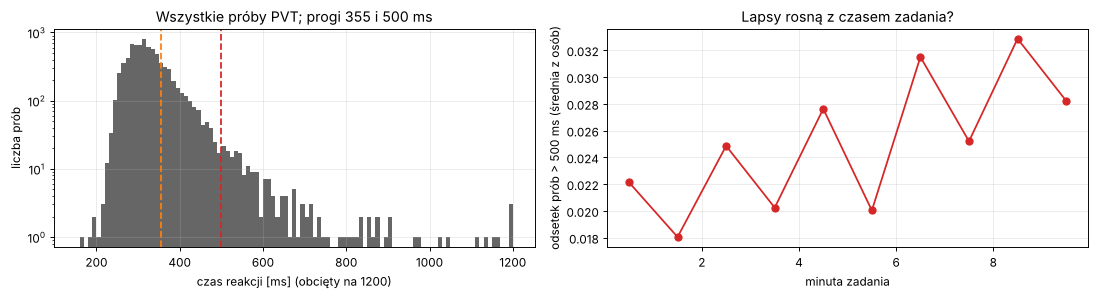

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
allrt = pd.concat([t.assign(subject=s) for (s, _), t in TRIALS.items()])
axes[0].hist(allrt.rt_ms.clip(upper=1200), bins=np.arange(150, 1210, 10), color="0.4")
for x, c in [(LAPSE_B_MS, "tab:orange"), (LAPSE_MS, "tab:red")]:
    axes[0].axvline(x, color=c, ls="--")
axes[0].set_yscale("log"); axes[0].set_xlabel("czas reakcji [ms] (obcięty na 1200)"); axes[0].set_ylabel("liczba prób")
axes[0].set_title("Wszystkie próby PVT; progi 355 i 500 ms")
rows = []
for (s, ses), t in TRIALS.items():
    info = RECS[(RECS.subject == s) & (RECS.session == ses)].iloc[0]
    rows.append(pd.DataFrame({"subject": s, "minute": ((t.t - info.t0) // 60).astype(int), "lapse": t.rt_ms > LAPSE_MS}))
lm = pd.concat(rows).groupby(["subject", "minute"]).lapse.mean().unstack()
lm = lm.loc[:, lm.columns < 10]
axes[1].plot(lm.columns + 0.5, lm.mean(0), "o-", color="tab:red")
axes[1].set_xlabel("minuta zadania"); axes[1].set_ylabel("odsetek prób > 500 ms (średnia z osób)")
axes[1].set_title("Lapsy rosną z czasem zadania?")
plt.tight_layout(); plt.show()

## 3. Punkty predykcji i AUC pojedynczych predyktorów (na osobę)

Co 10 s (czas τ) liczymy z przeszłości: średni z-score wyrazistości alfy (`alpha_mean`), maksimum wskaźnika szybkiego
(`alpha_max`), średni z-score mocy alfa O1/O2 (`occ_mean`), czas zadania, średni RT i liczbę lapsów w poprzedniej minucie.
Cel: czy w [τ, τ + 60 s) wystąpi laps. Kierunek każdego predyktora jest ustalony z góry (więcej = większe ryzyko),
więc AUC pojedynczej cechy nie wymaga uczenia. AUC < 0,5 znaczy „odwrotnie, niż zakładamy”.
Punkty co 10 s nakładają się (cel 60 s), dlatego nie liczymy z nich p-wartości; niepewność bierzemy z rozrzutu między osobami.

Do analizy AUC wchodzą osoby z co najmniej 3 lapsami w analizowanym okresie (wszystkie trzy sesje razem).

In [10]:
rng = np.random.default_rng(0)
N_BOOT = 2000
MIN_LAPSES = 3       # a person enters AUC analysis with >= 3 lapses (RT > 500 ms) inside the analysed period

FEATS = ["alpha_mean", "alpha_max", "occ_mean", "tot_min", "prev_rt", "prev_lapses", "prev_slow"]
A = ANCH.dropna(subset=["alpha_mean", "alpha_max", "occ_mean", "prev_rt", "y60"]).copy()


def summarize(vals, name=""):
    """Distribution over people: median, IQR, share > 0.5, bootstrap 95% CI of the median (resampling people)."""
    v = np.asarray(pd.Series(vals).dropna())
    boot = np.median(rng.choice(v, (N_BOOT, len(v))), axis=1)
    return dict(co=name, n_osob=len(v), mediana=np.median(v), q25=np.percentile(v, 25), q75=np.percentile(v, 75),
                ci95_lo=np.percentile(boot, 2.5), ci95_hi=np.percentile(boot, 97.5),
                powyzej_05=f"{(v > 0.5).sum()}/{len(v)}")


def auc_or_nan(y, s):
    y, s = np.asarray(y), np.asarray(s)
    ok = ~np.isnan(s)
    y, s = y[ok], s[ok]
    return roc_auc_score(y, s) if 0 < y.sum() < len(y) else np.nan


def lapse_counts(thr=LAPSE_MS):
    """Distinct lapses per person whose stimulus lies inside some analysed 60 s target window."""
    out = {}
    for sub, g in A.groupby("subject"):
        n = 0
        for ses, gs in g.groupby("session"):
            tr = TRIALS[sub, ses]
            lo, hi = gs.tau.min(), gs.tau.max() + 60
            n += int(((tr.t >= lo) & (tr.t < hi) & (tr.rt_ms > thr)).sum())
        out[sub] = n
    return pd.Series(out)

In [11]:
SINGLE = {"alpha_mean": "alfa: średni z wyrazistości, ostatnie 60 s",
          "alpha_max": "alfa: maks. wskaźnika szybkiego (mediana 5 okien)",
          "occ_mean": "alfa: średni z mocy 8–12 Hz O1/O2",
          "tot_min": "baza (a): czas zadania",
          "prev_rt": "baza (b): średni RT w poprzedniej minucie",
          "prev_lapses": "baza (b): lapsy w poprzedniej minucie"}


def single_auc_table(target, min_lapses=MIN_LAPSES, thr=LAPSE_MS):
    n_l = lapse_counts(thr)
    keep = n_l.index[n_l >= min_lapses]
    per = {f: A[A.subject.isin(keep)].groupby("subject").apply(lambda g: auc_or_nan(g[target], g[f]))
           for f in SINGLE}
    per = pd.DataFrame(per)
    return per, pd.DataFrame([summarize(per[f], SINGLE[f]) for f in SINGLE]).round(3)

In [12]:
nl = lapse_counts()
print(f"punkty predykcji z kompletem cech: {len(A)} (odsetek z lapsem w ciągu 60 s: {A.y60.mean():.2f})")
print(f"osoby z >= {MIN_LAPSES} lapsami w analizowanym okresie: {(nl >= MIN_LAPSES).sum()} z {len(nl)}; "
      f"lapsy u nich razem: {nl[nl >= MIN_LAPSES].sum()}")
PER60, TAB60 = single_auc_table("y60")
print("\nCel: laps (> 500 ms) w następnych 60 s. AUC na osobę:")
print(TAB60.to_string(index=False))
PER30, TAB30 = single_auc_table("y30")
print("\nCel: laps w następnych 30 s:")
print(TAB30.to_string(index=False))
nlb = lapse_counts(LAPSE_B_MS)
PERB, TABB = single_auc_table("yb60", thr=LAPSE_B_MS)
print(f"\nCel: RT > 355 ms (próg PVT-B) w następnych 60 s (odsetek punktów z celem = 1: {A.yb60.mean():.2f}):")
print(TABB.to_string(index=False))

punkty predykcji z kompletem cech: 3642 (odsetek z lapsem w ciągu 60 s: 0.19)
osoby z >= 3 lapsami w analizowanym okresie: 20 z 29; lapsy u nich razem: 146



Cel: laps (> 500 ms) w następnych 60 s. AUC na osobę:
                                               co  n_osob  mediana   q25   q75  ci95_lo  ci95_hi powyzej_05
       alfa: średni z wyrazistości, ostatnie 60 s      20    0.523 0.425 0.626    0.431    0.612      10/20
alfa: maks. wskaźnika szybkiego (mediana 5 okien)      20    0.512 0.403 0.606    0.430    0.595      11/20
                alfa: średni z mocy 8–12 Hz O1/O2      20    0.485 0.426 0.583    0.448    0.564      10/20
                           baza (a): czas zadania      20    0.559 0.456 0.642    0.494    0.639      14/20
        baza (b): średni RT w poprzedniej minucie      20    0.560 0.511 0.635    0.532    0.628      15/20
            baza (b): lapsy w poprzedniej minucie      20    0.468 0.434 0.556    0.438    0.541       8/20



Cel: laps w następnych 30 s:
                                               co  n_osob  mediana   q25   q75  ci95_lo  ci95_hi powyzej_05
       alfa: średni z wyrazistości, ostatnie 60 s      20    0.584 0.427 0.606    0.441    0.598      12/20
alfa: maks. wskaźnika szybkiego (mediana 5 okien)      20    0.527 0.421 0.617    0.437    0.593      10/20
                alfa: średni z mocy 8–12 Hz O1/O2      20    0.503 0.409 0.569    0.421    0.550      11/20
                           baza (a): czas zadania      20    0.569 0.444 0.640    0.462    0.615      13/20
        baza (b): średni RT w poprzedniej minucie      20    0.615 0.531 0.658    0.549    0.656      16/20
            baza (b): lapsy w poprzedniej minucie      20    0.452 0.432 0.562    0.437    0.538       8/20



Cel: RT > 355 ms (próg PVT-B) w następnych 60 s (odsetek punktów z celem = 1: 0.79):
                                               co  n_osob  mediana   q25   q75  ci95_lo  ci95_hi powyzej_05
       alfa: średni z wyrazistości, ostatnie 60 s      22    0.471 0.385 0.541    0.386    0.519       8/22
alfa: maks. wskaźnika szybkiego (mediana 5 okien)      22    0.489 0.365 0.547    0.459    0.545      10/22
                alfa: średni z mocy 8–12 Hz O1/O2      22    0.495 0.458 0.557    0.464    0.536       9/22
                           baza (a): czas zadania      22    0.651 0.532 0.697    0.547    0.692      18/22
        baza (b): średni RT w poprzedniej minucie      22    0.520 0.484 0.614    0.490    0.587      13/22
            baza (b): lapsy w poprzedniej minucie      22    0.500 0.482 0.560    0.490    0.553       9/22


**Uwaga do progu 355 ms:** w 10-minutowym PVT większość minut zawiera choć jedną reakcję > 355 ms, więc cel „czy będzie
choć jedna” jest prawdziwy w większości punktów (odsetek wypisany wyżej) i mało informacyjny. Poniżej, jako miarę ciągłą,
sprawdzamy też korelację alfy z **odsetkiem** reakcji > 355 ms w następnej minucie.

In [13]:
rows = []
for (sub, ses), tr in TRIALS.items():
    g = A[(A.subject == sub) & (A.session == ses)]
    for _, r in g.iterrows():
        fut = tr[(tr.t >= r.tau) & (tr.t < r.tau + 60)]
        rows.append((sub, r.alpha_mean, r.tot_min, r.prev_rt, (fut.rt_ms > LAPSE_B_MS).mean(), fut.rt_ms.mean()))
F = pd.DataFrame(rows, columns=["subject", "alpha_mean", "tot_min", "prev_rt", "frac355", "rt_next"])
from scipy.stats import spearmanr
cor = F.groupby("subject").apply(lambda g: pd.Series({
    "alfa~odsetek>355": spearmanr(g.alpha_mean, g.frac355)[0],
    "alfa~RT nast. min": spearmanr(g.alpha_mean, g.rt_next)[0],
    "RT poprz.~RT nast.": spearmanr(g.prev_rt, g.rt_next)[0],
    "czas~RT nast.": spearmanr(g.tot_min, g.rt_next)[0]}))
out = []
for c in cor:
    s = summarize(cor[c], c); s["powyzej_05"] = f"r>0: {(cor[c] > 0).sum()}/{cor[c].notna().sum()}"; out.append(s)
print("Korelacja Spearmana w obrębie osoby (punkty co 10 s, nakładające się):")
print(pd.DataFrame(out).rename(columns={"powyzej_05": "dodatnie"}).round(3).to_string(index=False))

Korelacja Spearmana w obrębie osoby (punkty co 10 s, nakładające się):
                co  n_osob  mediana    q25   q75  ci95_lo  ci95_hi   dodatnie
  alfa~odsetek>355      29   -0.022 -0.158 0.260   -0.109    0.175 r>0: 11/29
 alfa~RT nast. min      29   -0.078 -0.267 0.138   -0.123    0.134 r>0: 13/29
RT poprz.~RT nast.      29    0.185  0.062 0.375    0.113    0.323 r>0: 22/29
     czas~RT nast.      29    0.237  0.073 0.342    0.166    0.318 r>0: 25/29


### AUC w obrębie jednego nagrania

AUC na osobę łączy trzy sesje. Dla kontroli liczymy też AUC w obrębie pojedynczego nagrania, tylko dla nagrań z co najmniej
3 lapsami (inaczej AUC jest losowe).

In [14]:
rec_auc = []
for (sub, ses), g in A.groupby(["subject", "session"]):
    tr = TRIALS[sub, ses]
    n = int(((tr.t >= g.tau.min()) & (tr.t < g.tau.max() + 60) & (tr.rt_ms > LAPSE_MS)).sum())
    if n >= 3:
        rec_auc.append(dict(subject=sub, session=ses, n_lapses=n,
                            **{f: auc_or_nan(g.y60, g[f]) for f in ["alpha_mean", "alpha_max", "tot_min", "prev_rt"]}))
REC_AUC = pd.DataFrame(rec_auc)
print(f"nagrania z >= 3 lapsami w analizowanym okresie: {len(REC_AUC)} (osób: {REC_AUC.subject.nunique()})")
print(pd.DataFrame([summarize(REC_AUC[f], f) for f in ["alpha_mean", "alpha_max", "tot_min", "prev_rt"]])
      .rename(columns={"n_osob": "n_nagran"}).round(3).to_string(index=False))

nagrania z >= 3 lapsami w analizowanym okresie: 23 (osób: 13)
        co  n_nagran  mediana   q25   q75  ci95_lo  ci95_hi powyzej_05
alpha_mean        23    0.457 0.387 0.625    0.415    0.604      10/23
 alpha_max        23    0.467 0.348 0.641    0.421    0.589      11/23
   tot_min        23    0.533 0.424 0.658    0.426    0.634      14/23
   prev_rt        23    0.435 0.345 0.611    0.368    0.593      10/23


## 4. Czy alfa dodaje coś do prostych baz? (regresja logistyczna, walidacja bez przecieku)

Zestawy cech: czas; czas + zachowanie z poprzedniej minuty; sama alfa (`alpha_mean`, `alpha_max`); czas + alfa;
czas + zachowanie + alfa. Regresja logistyczna ze standaryzacją i regularyzacją (C = 0,3), bo zdarzeń jest mało.
Kluczowa liczba to **Δ AUC = (baza + alfa) − baza** w tej samej osobie, na tych samych punktach testowych.

Uwaga praktyczna: zachowanie z poprzedniej minuty to **miara zawartości informacji**, nie gotowa alternatywa,
bo w prawdziwej pracy nie ma ciągłego testu reakcji. Czas zadania jest dostępny zawsze.

In [15]:
SETS = {"czas": ["tot_min"],
        "czas+zachowanie": ["tot_min", "prev_rt", "prev_lapses"],
        "alfa": ["alpha_mean", "alpha_max"],
        "czas+alfa": ["tot_min", "alpha_mean", "alpha_max"],
        "czas+zachowanie+alfa": ["tot_min", "prev_rt", "prev_lapses", "alpha_mean", "alpha_max"]}


def model():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=1000))


def cv_loso(df, target, people):
    """Leave-one-person-out: weights learned on everybody else, AUC on the held-out person (all sessions)."""
    res = {}
    for sub in people:
        tr, te = df[df.subject != sub], df[df.subject == sub]
        res[sub] = {k: auc_or_nan(te[target], model().fit(tr[f], tr[target]).predict_proba(te[f])[:, 1])
                    for k, f in SETS.items()}
    return pd.DataFrame(res).T


def cv_forward(df, target, people):
    """Within person, time-forward: session k is predicted by a model trained on the same person's sessions < k.
    Predictions of all test sessions are pooled into one AUC per person."""
    res = {}
    for sub in people:
        g = df[df.subject == sub]
        sess = sorted(g.session.unique())
        preds = {k: [] for k in SETS}
        ys = []
        for i, ses in enumerate(sess[1:], start=1):
            tr, te = g[g.session.isin(sess[:i])], g[g.session == ses]
            if tr[target].sum() < 2 or tr[target].sum() == len(tr):
                continue
            ys.append(te[target].values)
            for k, f in SETS.items():
                preds[k].append(model().fit(tr[f], tr[target]).predict_proba(te[f])[:, 1])
        if ys:
            y = np.concatenate(ys)
            res[sub] = {k: auc_or_nan(y, np.concatenate(p)) for k, p in preds.items()}
    return pd.DataFrame(res).T


def cv_report(per, label):
    rows = [summarize(per[k], f"{label}: {k}") for k in SETS]
    for base in ["czas", "czas+zachowanie"]:
        full = base + "+alfa" if base == "czas+zachowanie" else "czas+alfa"
        d = (per[full] - per[base]).dropna()
        p = wilcoxon(d).pvalue if (d != 0).sum() >= 5 else np.nan
        r = summarize(d, f"{label}: Δ ({full}) − ({base})")
        r["powyzej_05"] = f"Δ>0: {(d > 0).sum()}/{len(d)}, Wilcoxon p={p:.2f}"
        rows.append(r)
    return pd.DataFrame(rows).round(3)

In [16]:
people = nl.index[nl >= MIN_LAPSES]
LOSO = cv_loso(A, "y60", people)
print("(1) Leave-one-person-out, cel: laps w następnych 60 s")
print(cv_report(LOSO, "LOSO").to_string(index=False))
FWD = cv_forward(A, "y60", people)
print(f"\n(2) W obrębie osoby, w przód w czasie (sesja k z modelu uczonego na sesjach < k); osoby z oceną: {len(FWD)}")
print(cv_report(FWD, "w przód").to_string(index=False))
LOSO30 = cv_loso(A, "y30", nl.index[nl >= MIN_LAPSES])
print("\n(1') Leave-one-person-out, cel: laps w następnych 30 s")
print(cv_report(LOSO30, "LOSO 30 s").to_string(index=False))

(1) Leave-one-person-out, cel: laps w następnych 60 s
                                                co  n_osob  mediana    q25    q75  ci95_lo  ci95_hi                 powyzej_05
                                        LOSO: czas      20    0.559  0.456  0.642    0.494    0.639                      14/20
                             LOSO: czas+zachowanie      20    0.543  0.464  0.634    0.483    0.632                      13/20
                                        LOSO: alfa      20    0.415  0.351  0.477    0.361    0.476                       3/20
                                   LOSO: czas+alfa      20    0.494  0.421  0.583    0.444    0.575                      10/20
                        LOSO: czas+zachowanie+alfa      20    0.542  0.461  0.626    0.482    0.623                      13/20
                      LOSO: Δ (czas+alfa) − (czas)      20   -0.021 -0.058 -0.005   -0.045   -0.011 Δ>0: 3/20, Wilcoxon p=0.01
LOSO: Δ (czas+zachowanie+alfa) − (czas+zachowanie)      2


(2) W obrębie osoby, w przód w czasie (sesja k z modelu uczonego na sesjach < k); osoby z oceną: 19
                                                   co  n_osob  mediana    q25   q75  ci95_lo  ci95_hi                  powyzej_05
                                        w przód: czas      19    0.473  0.344 0.601    0.359    0.596                        9/19
                             w przód: czas+zachowanie      19    0.503  0.371 0.615    0.377    0.601                       10/19
                                        w przód: alfa      19    0.443  0.310 0.575    0.344    0.549                        7/19
                                   w przód: czas+alfa      19    0.468  0.310 0.583    0.361    0.566                        7/19
                        w przód: czas+zachowanie+alfa      19    0.452  0.342 0.584    0.379    0.576                        9/19
                      w przód: Δ (czas+alfa) − (czas)      19   -0.003 -0.092 0.073   -0.072    0.066  Δ>0: 9/19, Wilco


(1') Leave-one-person-out, cel: laps w następnych 30 s
                                                     co  n_osob  mediana    q25    q75  ci95_lo  ci95_hi                 powyzej_05
                                        LOSO 30 s: czas      20    0.569  0.444  0.640    0.472    0.615                      13/20
                             LOSO 30 s: czas+zachowanie      20    0.599  0.519  0.657    0.544    0.647                      15/20
                                        LOSO 30 s: alfa      20    0.390  0.327  0.459    0.332    0.452                       4/20
                                   LOSO 30 s: czas+alfa      20    0.504  0.362  0.598    0.396    0.588                      10/20
                        LOSO 30 s: czas+zachowanie+alfa      20    0.595  0.519  0.642    0.538    0.628                      15/20
                      LOSO 30 s: Δ (czas+alfa) − (czas)      20   -0.031 -0.045 -0.019   -0.039   -0.026 Δ>0: 4/20, Wilcoxon p=0.00
LOSO 30 s: Δ (czas+z

In [17]:
coef = model().fit(A[SETS["czas+zachowanie+alfa"]], A["y60"])[-1].coef_[0]
print("Współczynniki modelu na wszystkich danych (cechy standaryzowane), tylko do interpretacji kierunku:")
print(pd.Series(coef, index=SETS["czas+zachowanie+alfa"]).round(3).to_string())

Współczynniki modelu na wszystkich danych (cechy standaryzowane), tylko do interpretacji kierunku:
tot_min        0.044
prev_rt        0.569
prev_lapses   -0.005
alpha_mean     0.020
alpha_max     -0.062


## 5. Widok zdarzeń: co robi alfa przed lapsem?

Każdy laps (RT > 500 ms, co najmniej 30 s po kalibracji) wyrównujemy do chwili bodźca. Dla każdego lapsu bierzemy 3 próby
kontrolne z tego samego nagrania (RT ≤ 500 ms, najbliżej w czasie zadania, co najmniej 20 s od jakiegokolwiek lapsu).
Śledzimy wskaźnik szybki produktu (mediana 5 okien z-score'u wyrazistości alfy) w wersji przyczynowej:
w chwili t widzimy tylko okno, które skończyło się przed t. Średnia najpierw w osobie, potem między osobami
(przedział ufności 95% z bootstrapu po osobach).

In [18]:
LAG = np.arange(-90, 21)        # s relative to stimulus onset of the lapse trial
N_CTRL = 3                      # matched control trials per lapse
EXCL_S = 20                     # controls must be >= 20 s from any lapse


def trace_at(W, t_ref, col="fast"):
    """Value of the causal fast index available at t_ref + lag (window ending at or before that moment)."""
    te, v = W.t_end.values, W[col].values
    idx = np.searchsorted(te, t_ref + LAG, side="right") - 1
    out = np.where(idx >= 0, v[np.clip(idx, 0, None)], np.nan)
    out[(t_ref + LAG) - te[np.clip(idx, 0, None)] > 1.5] = np.nan      # no fresh window (gap / end)
    return out


ev_rows = []
for (sub, ses), tr in TRIALS.items():
    W, info = WINS[sub, ses], RECS[(RECS.subject == sub) & (RECS.session == ses)].iloc[0]
    ok_time = tr.t >= info.cal_end + 30                                  # z-score must exist for >= 30 s before
    lapses = tr[ok_time & (tr.rt_ms > LAPSE_MS)]
    ctrl_pool = tr[ok_time & (tr.rt_ms <= LAPSE_MS)]
    lap_all = tr.t[tr.rt_ms > LAPSE_MS].values
    if len(lap_all):
        ctrl_pool = ctrl_pool[np.min(np.abs(ctrl_pool.t.values[:, None] - lap_all[None]), axis=1) >= EXCL_S]
    for _, L in lapses.iterrows():
        ev_rows.append(dict(subject=sub, session=ses, kind="laps", t=L.t, trace=trace_at(W, L.t)))
        near = ctrl_pool.iloc[np.argsort(np.abs(ctrl_pool.t.values - L.t))[:N_CTRL]]   # matched on time on task
        for _, C in near.iterrows():
            ev_rows.append(dict(subject=sub, session=ses, kind="kontrola", t=C.t, trace=trace_at(W, C.t)))
EV = pd.DataFrame(ev_rows)


def person_traces(EV):
    out = {}
    for sub, g in EV.groupby("subject"):
        lap = np.vstack(g[g.kind == "laps"].trace.values)
        ctl = np.vstack(g[g.kind == "kontrola"].trace.values) if (g.kind == "kontrola").any() else None
        if ctl is None:
            continue
        out[sub] = dict(lap=np.nanmean(lap, 0), ctl=np.nanmean(ctl, 0), n_lap=len(lap))
    return out


PT = person_traces(EV)
print(f"lapsy w widoku zdarzeń: {(EV.kind == 'laps').sum()} u {len(PT)} osób; kontrole: {(EV.kind == 'kontrola').sum()}")

lapsy w widoku zdarzeń: 164 u 25 osób; kontrole: 489


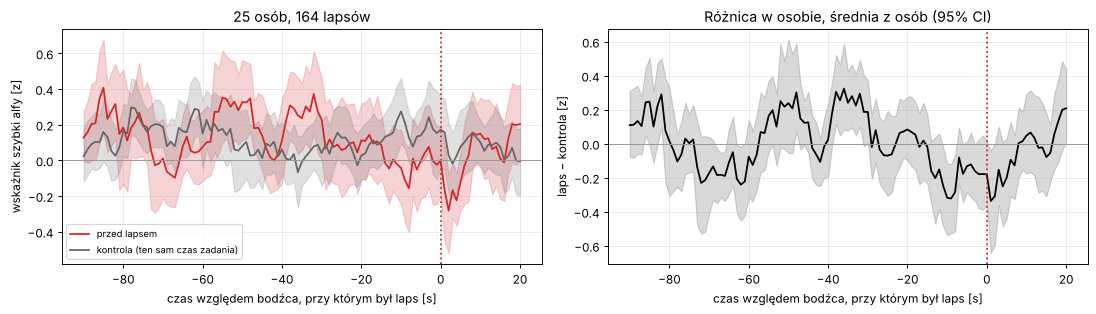

    okno_s  n_osob  srednia_roznica_z  mediana dodatnie  p_wilcoxon
[-90, -60)      25             -0.025   -0.035    10/25       0.382
[-60, -30)      25              0.142    0.070    17/25       0.037
[-30, -10)      25             -0.018    0.064    15/25       0.778
  [-10, 0)      25             -0.192   -0.119     6/25       0.001
   [0, 10)      25             -0.164   -0.179     6/25       0.032
  [10, 21)      25              0.066   -0.109    10/25       0.600


In [19]:
subs_ev = [s for s in PT if PT[s]["n_lap"] >= 1]
lapm = np.vstack([PT[s]["lap"] for s in subs_ev])
ctlm = np.vstack([PT[s]["ctl"] for s in subs_ev])
diff = lapm - ctlm


def boot_ci(M):
    idx = rng.integers(0, len(M), (N_BOOT, len(M)))
    b = np.nanmean(M[idx], axis=1)
    return np.nanmean(M, 0), np.nanpercentile(b, 2.5, 0), np.nanpercentile(b, 97.5, 0)


fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for M, c, lab in [(lapm, "tab:red", "przed lapsem"), (ctlm, "0.4", "kontrola (ten sam czas zadania)")]:
    m, lo, hi = boot_ci(M)
    axes[0].plot(LAG, m, color=c, label=lab); axes[0].fill_between(LAG, lo, hi, color=c, alpha=0.2)
m, lo, hi = boot_ci(diff)
axes[1].plot(LAG, m, color="k"); axes[1].fill_between(LAG, lo, hi, color="k", alpha=0.15)
for ax in axes:
    ax.axvline(0, color="tab:red", ls=":"); ax.axhline(0, color="0.6", lw=0.8)
    ax.set_xlabel("czas względem bodźca, przy którym był laps [s]")
axes[0].set_ylabel("wskaźnik szybki alfy [z]"); axes[0].legend(fontsize=8)
axes[0].set_title(f"{len(subs_ev)} osób, {(EV.kind == 'laps').sum()} lapsów")
axes[1].set_ylabel("laps − kontrola [z]"); axes[1].set_title("Różnica w osobie, średnia z osób (95% CI)")
plt.tight_layout(); plt.show()

bins = [(-90, -60), (-60, -30), (-30, -10), (-10, 0), (0, 10), (10, 21)]
rows = []
for a, b in bins:
    sel = (LAG >= a) & (LAG < b)
    d = np.nanmean(diff[:, sel], 1)
    d = d[~np.isnan(d)]
    rows.append(dict(okno_s=f"[{a}, {b})", n_osob=len(d), srednia_roznica_z=d.mean(), mediana=np.median(d),
                     dodatnie=f"{(d > 0).sum()}/{len(d)}", p_wilcoxon=wilcoxon(d).pvalue))
LEAD = pd.DataFrame(rows).round(3)
print(LEAD.to_string(index=False))

## 6. Przełożenie na produkt: ostrzeżenie i test reakcji

Reguła: gdy wskaźnik szybki przekroczy próg, panel wysyła ostrzeżenie (prośbę o test reakcji), potem przez 60 s nie ostrzega
ponownie. Ostrzeżenie jest „trafione”, gdy w ciągu 60 s po nim wystąpi laps. Liczymy:
- **czułość**: jaki odsetek lapsów poprzedziło ostrzeżenie w ciągu 60 s,
- **fałszywe ostrzeżenia na godzinę**: ostrzeżenia bez lapsu w ciągu 60 s,
- **poziom losowy**: odsetek czasu, który „pokrywają” ostrzeżenia (60 s po każdym). Tyle czułości dałyby ostrzeżenia
  rozrzucone losowo z tą samą częstością. Liczy się **czułość ponad poziom losowy**.

Progi ustalone z góry: z = 1,0; 1,5; 2,0 oraz 2,5 (próg detektora lapsów w produkcie; w wariancie produktu
dodatkowo przez ≥ 3 s). Na koniec próg wybrany osobno dla każdej osoby na sesjach S1–S2 i sprawdzony na S3.

In [20]:
REFRACT_S = 60      # after a warning the probe runs; no new warning for 60 s
HORIZON_S = 60      # a warning is "true" if a lapse follows within 60 s


def warnings_for(W, info, thr, min_windows=1):
    """Warning = fast index above thr for min_windows consecutive windows (after calibration),
    then a 60 s refractory period. min_windows=3 at thr=2.5 is the product's lapse detector."""
    te, f = W.t_end.values, W.fast.values
    w, last, run = [], -np.inf, 0
    for t, v in zip(te, f):
        run = run + 1 if (not np.isnan(v) and v > thr) else 0
        if t > info.cal_end and run >= min_windows and t - last >= REFRACT_S:
            w.append(t)
            last = t
    return np.array(w)


def warn_eval(thr, recs, min_windows=1):
    rows = []
    for _, info in recs.iterrows():
        W, tr = WINS[info.subject, info.session], TRIALS[info.subject, info.session]
        w = warnings_for(W, info, thr, min_windows)
        lap = tr.t[(tr.rt_ms > LAPSE_MS) & (tr.t > info.cal_end + HORIZON_S)].values    # lapses we could warn for
        hit = np.array([((w < s) & (w >= s - HORIZON_S)).any() for s in lap], bool)
        lap_all = tr.t[tr.rt_ms > LAPSE_MS].values
        true_w = np.array([((lap_all > x) & (lap_all <= x + HORIZON_S)).any() for x in w], bool)
        mon_h = (info.t1 - info.cal_end) / 3600
        # chance level: share of the monitored time covered by the 60 s after a warning
        grid = np.arange(info.cal_end + HORIZON_S, info.t1, 1.0)
        cover = np.mean([((w < g) & (w >= g - HORIZON_S)).any() for g in grid]) if len(grid) else np.nan
        rows.append(dict(subject=info.subject, session=info.session, thr=thr, n_lapses=len(lap), n_hit=int(hit.sum()),
                         n_warn=len(w), n_false=int((~true_w).sum()), hours=mon_h, cover=cover))
    return pd.DataFrame(rows)


def warn_summary(R):
    g = R.groupby("subject").sum(numeric_only=True)
    g["cover"] = R.groupby("subject").apply(lambda x: np.average(x.cover, weights=x.hours))
    g = g[g.n_lapses > 0]
    g["sens"] = g.n_hit / g.n_lapses
    g["false_per_h"] = g.n_false / g.hours
    g["sens_minus_chance"] = g.sens - g.cover
    return g

In [21]:
rows, PER_WARN = [], {}
for thr, k, lab in [(1.0, 1, "z > 1,0"), (1.5, 1, "z > 1,5"), (2.0, 1, "z > 2,0"), (2.5, 1, "z > 2,5"),
                    (2.5, 3, "z > 2,5 przez ≥ 3 s (detektor produktu)")]:
    R = warn_eval(thr, RECS, k)
    g = warn_summary(R)
    PER_WARN[lab] = g
    tot = R.sum(numeric_only=True)
    cover_all = np.average(R.cover, weights=R.hours)
    d = g.sens_minus_chance
    rows.append({"próg": lab, "osoby": len(g), "lapsy": int(tot.n_lapses),
                 "czułość (wszystkie lapsy)": tot.n_hit / tot.n_lapses,
                 "poziom losowy": cover_all,
                 "ostrz./h": tot.n_warn / tot.hours, "fałszywe/h": tot.n_false / tot.hours,
                 "mediana czułości na osobę": g.sens.median(),
                 "mediana fałszywych/h na osobę": g.false_per_h.median(),
                 "czułość − losowy: mediana na osobę": d.median(),
                 "osoby z czułością > losowy": f"{(d > 0).sum()}/{len(d)}"})
WARN = pd.DataFrame(rows).round(2)
print(f"monitorowany czas po kalibracji: {warn_eval(1.0, RECS).hours.sum():.1f} h w {len(RECS)} nagraniach")
print(WARN.T.to_string())

monitorowany czas po kalibracji: 13.1 h w 87 nagraniach
                                          0        1        2        3                                        4
próg                                z > 1,0  z > 1,5  z > 2,0  z > 2,5  z > 2,5 przez ≥ 3 s (detektor produktu)
osoby                                    25       25       25       25                                       25
lapsy                                   156      156      156      156                                      156
czułość (wszystkie lapsy)              0.54     0.31     0.19     0.08                                     0.04
poziom losowy                          0.59     0.34      0.2     0.11                                     0.06
ostrz./h                              37.08    20.84    11.88     7.05                                     3.98
fałszywe/h                            31.11    17.09     9.73      5.9                                     3.45
mediana czułości na osobę               0.5     

In [22]:
GRID = np.arange(0.5, 3.01, 0.25)
rows = []
for sub in RECS.subject.unique():
    rs = RECS[RECS.subject == sub]
    train, test = rs[rs.session.isin(["S1", "S2"])], rs[rs.session == "S3"]
    if len(test) == 0:
        continue
    tr_eval = {thr: warn_eval(thr, train) for thr in GRID}
    if tr_eval[GRID[0]].n_lapses.sum() == 0:
        continue
    gain = {thr: e.n_hit.sum() / e.n_lapses.sum() - np.average(e.cover, weights=e.hours) for thr, e in tr_eval.items()}
    best = max(gain, key=lambda t: (round(gain[t], 6), t))       # ties -> higher threshold (fewer warnings)
    te = warn_eval(best, test)
    s = te.sum(numeric_only=True)
    if s.n_lapses == 0:
        continue
    rows.append(dict(subject=sub, thr=best, gain_train=gain[best], n_lapses_test=int(s.n_lapses),
                     sens_test=s.n_hit / s.n_lapses, chance_test=te.cover.iloc[0], false_per_h_test=s.n_false / s.hours))
OP = pd.DataFrame(rows)
print(f"osoby z lapsami i w S1–S2, i w S3: {len(OP)}")
print(OP.round(2).to_string(index=False))
d = OP.sens_test - OP.chance_test
print(f"\nS3: czułość mediana {OP.sens_test.median():.2f}, poziom losowy mediana {OP.chance_test.median():.2f}, "
      f"czułość − losowy: mediana {d.median():.2f}, > 0 u {(d > 0).sum()}/{len(d)}; "
      f"fałszywe/h mediana {OP.false_per_h_test.median():.1f}")

osoby z lapsami i w S1–S2, i w S3: 19
subject  thr  gain_train  n_lapses_test  sens_test  chance_test  false_per_h_test
 sub-01 2.00        0.19              1       0.00         0.00              0.00
 sub-02 0.75        0.15              6       0.83         0.75             20.01
 sub-04 0.75        0.35              4       1.00         0.92             36.69
 sub-06 0.75       -0.04              6       1.00         0.87             20.79
 sub-08 0.50        0.14              4       0.75         0.91             44.97
 sub-09 2.75        0.42              1       0.00         0.00              0.00
 sub-11 1.50        0.28              5       0.00         0.00              0.00
 sub-13 2.00        0.04              4       0.00         0.00              0.00
 sub-14 3.00        0.00              2       0.00         0.00              0.00
 sub-15 3.00        0.00              7       0.00         0.00              0.00
 sub-18 1.00        0.32              4       0.25         0

## 7. Wykres na slajd

In [23]:
SLIDE_HEADLINE = 'alfa nie ostrzega przed lapsem: AUC na osobę 0,52 (≈ losowo), nic nie dodaje do czasu zadania i RT'

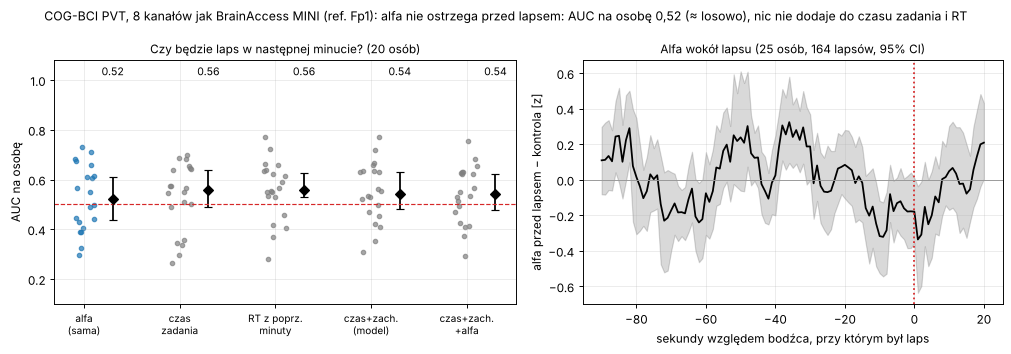

pvt-alpha-early-warning-cogbci.png 141 kB


In [24]:
SLIDE = Path("../../docs/img/pvt-alpha-early-warning-cogbci.png")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
items = [("alfa\n(sama)", PER60["alpha_mean"]), ("czas\nzadania", PER60["tot_min"]),
         ("RT z poprz.\nminuty", PER60["prev_rt"]), ("czas+zach.\n(model)", LOSO["czas+zachowanie"]),
         ("czas+zach.\n+alfa", LOSO["czas+zachowanie+alfa"])]
for i, (lab, v) in enumerate(items):
    v = v.dropna()
    s = summarize(v)
    ax.scatter(np.full(len(v), i) + rng.uniform(-0.12, 0.12, len(v)), v, s=14, color="tab:blue" if i == 0 else "0.5", alpha=0.7)
    ax.errorbar(i + 0.3, s["mediana"], yerr=[[s["mediana"] - s["ci95_lo"]], [s["ci95_hi"] - s["mediana"]]],
                fmt="D", color="k", capsize=3)
    ax.text(i + 0.3, 1.02, f"{s['mediana']:.2f}", ha="center", fontsize=9)
ax.axhline(0.5, color="tab:red", ls="--", lw=1)
ax.set_xticks(range(len(items))); ax.set_xticklabels([l for l, _ in items], fontsize=8.5)
ax.set_ylim(0.1, 1.08); ax.set_ylabel("AUC na osobę")
ax.set_title(f"Czy będzie laps w następnej minucie? ({len(PER60)} osób)", fontsize=10)
ax = axes[1]
m, lo, hi = boot_ci(diff)
ax.plot(LAG, m, color="k"); ax.fill_between(LAG, lo, hi, color="k", alpha=0.15)
ax.axvline(0, color="tab:red", ls=":"); ax.axhline(0, color="0.6", lw=0.8)
ax.set_xlabel("sekundy względem bodźca, przy którym był laps")
ax.set_ylabel("alfa przed lapsem − kontrola [z]")
ax.set_title(f"Alfa wokół lapsu ({len(subs_ev)} osób, {(EV.kind == 'laps').sum()} lapsów, 95% CI)", fontsize=10)
fig.suptitle("COG-BCI PVT, 8 kanałów jak BrainAccess MINI (ref. Fp1): " + SLIDE_HEADLINE, fontsize=10.5)
plt.tight_layout()
fig.savefig(SLIDE, dpi=110, bbox_inches="tight")
plt.show()
print(SLIDE.resolve().name, f"{SLIDE.stat().st_size / 1024:.0f} kB")

## 8. Wnioski

**W skrócie: alfa potyliczna przy otwartych oczach nie przewiduje lapsu w następnej minucie.** AUC na osobę:
mediana **0,52** (IQR 0,43–0,63; 95% CI mediany 0,43–0,61; AUC > 0,5 u 10 z 20 osób), czyli poziom losowy.
Dołożona do prostych baz (czas zadania + RT z poprzedniej minuty) **nic nie dodaje**: Δ AUC mediana −0,005
(leave-one-person-out; Δ > 0 u 6/20) i +0,01 (model w obrębie osoby, w przód w czasie; Δ > 0 u 12/19, p = 0,89).
**Wczesny test reakcji wyzwalany alfą nie ma uzasadnienia w tych danych:** przy każdym progu z góry (z = 1,0; 1,5; 2,0; 2,5)
czułość jest równa albo niższa od poziomu losowego (np. z > 1,5: 31% lapsów poprzedzonych ostrzeżeniem przy 34% losowo,
17 fałszywych ostrzeżeń na godzinę).

**Szczegóły (wszystkie liczby z komórek wyżej):**

1. **Dane.** 29 osób, 87 nagrań PVT (ok. 10 min, 90 bodźców), 13,1 h po kalibracji. Lapsów > 500 ms jest mało: 200 razem,
   mediana 1 na nagranie; 25 nagrań i 4 osoby nie mają żadnego. Do AUC na osobę weszło 20 osób z ≥ 3 lapsami (146 lapsów,
   3642 punkty predykcji co 10 s). Falstarty: 40 znaczników „błąd w przerwie” i 27 reakcji zapisanych w chwili bodźca (wyłączone z RT).
   Pliki `behavioral/PVT.mat` w COG-BCI nie odpowiadają nagraniom (tylko 2 różne pliki na 87), więc RT bierzemy ze znaczników EEG.
2. **Pojedyncze predyktory, cel 60 s.** Alfa: wyrazistość 0,52, maksimum wskaźnika szybkiego 0,51, moc 8–12 Hz O1/O2 0,49.
   Bazy: czas zadania 0,56 (14/20 > 0,5), średni RT z poprzedniej minuty 0,56 (95% CI 0,53–0,63; 15/20).
   Bazy są słabe, ale alfa jest jeszcze słabsza. Przy celu 30 s wyrazistość alfy ma medianę 0,58, ale CI 0,44–0,60
   obejmuje 0,5 (12/20), a RT z poprzedniej minuty ma 0,62 (CI 0,55–0,66). W obrębie pojedynczych nagrań z ≥ 3 lapsami
   (23 nagrania, 13 osób) alfa ma medianę 0,46. Korelacja alfy z RT w następnej minucie: mediana r = −0,08 (dodatnia u 13/29 osób),
   a czasu zadania z RT: r = +0,24 (dodatnia u 25/29). Dla progu PVT-B (355 ms) alfa też nie działa (mediana 0,47).
3. **Modele bez przecieku.** Bez danej osoby: czas 0,56, czas + zachowanie 0,54, czas + zachowanie + alfa 0,54.
   Sama alfa w modelu uczonym na innych osobach daje 0,42 (> 0,5 tylko u 3/20). Kierunek związku alfy z lapsami
   nie przenosi się między ludźmi. W obrębie osoby (S1 → S2, S1 + S2 → S3) wszystkie modele są blisko 0,5 (mediany 0,44–0,50),
   co pokazuje też, że kilka lapsów na sesję to za mało, żeby uczyć osobisty model.
4. **Widok zdarzeń (25 osób, 164 lapsy, kontrole dobrane czasem zadania).** Przed lapsem nie widać wzrostu alfy.
   W ostatnich 10 s przed bodźcem wskaźnik jest nawet **niższy** niż w kontroli (−0,19 z; wyżej u 6/25 osób; Wilcoxon p = 0,001),
   a w oknie [−60, −30) s nieco wyższy (+0,14 z; 17/25; p = 0,037, co przy 6 testowanych oknach nie przetrwa poprawki
   na wielokrotne porównania). Efekty rzędu 0,1–0,2 z przy szumie wskaźnika rzędu 1 z są bezużyteczne do ostrzegania
   pojedynczej osoby. Spadek tuż przed lapsem to raczej nie alfa: przy referencji Fp1 mrugnięcia i ruchy oczu trafiają
   do O1/O2 i podnoszą moc 5–7 Hz, co obniża wyrazistość alfy. To hipoteza, nie sprawdziliśmy jej.
   **Odpowiedź na pytanie „ile sekund wyprzedzenia daje alfa?”: w tych danych żadnego.**
5. **Ostrzeżenia w praktyce.** Czułość ≈ poziom losowy przy każdym progu: z > 1,0: 54% wobec 59% losowo (31 fałszywych/h);
   z > 1,5: 31% wobec 34% (17/h); z > 2,0: 19% wobec 20% (9,7/h); z > 2,5: 8% wobec 11% (5,9/h).
   Próg wybrany osobno dla każdej osoby na S1–S2 i sprawdzony na S3 (19 osób): mediana czułości 0%, poziom losowy 14%,
   lepiej niż losowo u 7/19, mediana 13 fałszywych ostrzeżeń/h.
   Detektor lapsów z produktu (z > 2,5 przez ≥ 3 s) zadziałał w tym zadaniu ok. 4 razy na godzinę, ale nie w pobliżu lapsów
   (4% lapsów wobec 6% losowo, 3,5 zdarzenia/h bez lapsu). Ten detektor wykrywa zamykanie oczu i wybuchy alfy,
   a nie wolną reakcję przy otwartych oczach. To dwa różne zjawiska.

**Co to znaczy dla produktu:**
- **Nie** budujemy funkcji „EEG ostrzega przed lapsem, zanim się zdarzy” i nie mówimy tego w pitchu.
  Alfa może służyć do wykrywania zamykania oczu w trakcie (to pokazują notebooki 01 i 03), a nie do prognozy.
- Jeśli panel ma prosić o test reakcji, uczciwiej robić to **według harmonogramu** (np. co 15–30 min albo po czasie pracy)
  niż według progu alfy. Sam wynik testu (wolniejsze RT) jest najlepszym predyktorem następnych lapsów w tych danych
  (RT z poprzedniej minuty: AUC 0,56–0,62). Jeśli zespół mimo to chce wyzwalania przez EEG w demo, jedyny obroniony próg
  to wysoki próg produktu (z > 2,5 przez ≥ 3 s), z jasnym opisem „wykrycie zamykania oczu”, a nie „prognoza”.
- Kontekst (czas zadania) wygrywa z EEG także tutaj, co zgadza się z `docs/podstawy-naukowe.md` §5.

**Ograniczenia:**
- Uczestnicy byli wypoczęci, a PVT trwał tylko ok. 10 minut. Lapsów jest mało (mediana 1 na nagranie), więc AUC na osobę
  jest niepewne, a modele w obrębie osoby mają bardzo mało zdarzeń. Wynik zerowy nie wyklucza, że alfa ostrzega przy
  prawdziwej senności (noc, deprywacja snu, długa monotonna jazda). Tego te dane nie sprawdzają.
- Dane to 63-kanałowe EEG z żelem, z którego wycinamy 8 kanałów i przeliczamy do Fp1. Suche elektrody BrainAccess MINI
  będą miały więcej artefaktów, nie mniej.
- Filtr 1–40 Hz ma tu zerową fazę (offline). Produkt filtruje przyczynowo. Przerwa 2 s między predyktorem a celem
  chroni przed przeciekiem, ale wartości nie są identyczne z tymi na żywo.
- Punkty predykcji co 10 s nakładają się, więc nie liczymy z nich p-wartości. Niepewność bierzemy z rozrzutu między osobami.
- Kalibracja to pierwsza minuta zadania, jak w produkcie. Jeśli ktoś był senny od początku, jego z-score tego nie pokaże.

**Zgodność z dokumentacją zespołu:** `docs/podstawy-naukowe.md` §1 pisze, że alfa przy otwartych oczach rośnie,
gdy pojawiają się wtrącenia senności. U wypoczętych osób w 10-minutowym PVT nie widać tego przed lapsami behawioralnymi.
Nie jest to sprzeczność z literaturą (inne warunki), ale **nie wolno** cytować tego ustalenia jako dowodu, że nasz wskaźnik
przewiduje lapsy. Wzrost lapsów z czasem zadania jest tu słaby (ok. 2% prób w pierwszych minutach, ok. 3% w ostatnich),
mniejszy niż w badaniach z deprywacją snu (Lim i Dinges 2008).